In [41]:
%pip install statsmodels
%pip install scikit-learn

^C
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path
import pandas as pd

# Locate processed datasets
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
data_dir = project_root / "data" / "processed"

# Load datasets
datasets = {}

for file in sorted(data_dir.glob("*.csv")):
    name = file.stem.replace("_2024_2025", "")
    df = pd.read_csv(file)

    time_col = "from" if name == "carbon_intensity" else "startTime"
    df[time_col] = pd.to_datetime(df[time_col], utc=True)

    datasets[name] = df

print("Loaded datasets:", list(datasets))
print("Missing price values:",
      datasets["electricity_price"]["price"].isna().sum())

Loaded datasets: ['carbon_intensity', 'electricity_demand', 'electricity_generation', 'electricity_price']
Missing price values: 1


In [ ]:
import pandas as pd

price = datasets["electricity_price"].copy()
demand = datasets["electricity_demand"].copy()
generation = datasets["electricity_generation"].copy()

# 1. Inspect zero-volume periods
print("ZERO-VOLUME PERIODS")
print(
    price.loc[price["volume"] == 0,
              ["startTime", "price", "volume"]]
    .to_string(index=False)
)

# 2. Inspect extreme prices
print("\nTOP 10 HIGHEST PRICES")
print(
    price.nlargest(10, "price")[
        ["startTime", "price", "volume"]
    ].to_string(index=False)
)

print("\nTOP 10 LOWEST PRICES")
print(
    price.nsmallest(10, "price")[
        ["startTime", "price", "volume"]
    ].to_string(index=False)
)

# 3. Inspect INTGRNL availability
print("\nINTGRNL FIRST NON-MISSING OBSERVATIONS")
print(
    generation.loc[
        generation["INTGRNL"].notna(),
        ["startTime", "INTGRNL"]
    ].head(10).to_string(index=False)
)

# 4. Merge demand and generation for diagnostics
comparison = demand.merge(
    generation,
    on="startTime",
    how="inner",
    validate="one_to_one"
)

# Keep fuel generation separate from interconnectors
# and pumped storage to avoid ambiguous aggregation
fuel_columns = [
    "BIOMASS", "CCGT", "COAL", "NPSHYD",
    "NUCLEAR", "OCGT", "OIL", "OTHER", "WIND"
]

comparison["fuel_generation_sum"] = (
    comparison[fuel_columns].sum(axis=1)
)

corr = comparison[
    ["initialDemandOutturn", "fuel_generation_sum"]
].corr()

print("\nDEMAND VS FUEL GENERATION")
print(corr)

print("\nSUMMARY")
print(
    comparison[
        ["initialDemandOutturn", "fuel_generation_sum"]
    ].describe()
)

ZERO-VOLUME PERIODS
                startTime  price  volume
2025-06-27 08:00:00+00:00    0.0     0.0
2025-06-27 08:30:00+00:00    0.0     0.0
2025-06-27 10:00:00+00:00    0.0     0.0
2025-06-28 22:00:00+00:00    0.0     0.0
2025-06-28 22:30:00+00:00    0.0     0.0
2025-06-28 23:00:00+00:00    0.0     0.0
2025-06-28 23:30:00+00:00    0.0     0.0
2025-06-29 00:00:00+00:00    0.0     0.0
2025-06-29 00:30:00+00:00    0.0     0.0
2025-06-29 01:00:00+00:00    0.0     0.0
2025-09-06 12:00:00+00:00    0.0     0.0

TOP 10 HIGHEST PRICES
                startTime   price  volume
2025-01-08 16:30:00+00:00 1352.90 2196.20
2025-01-08 17:00:00+00:00 1309.12 1714.45
2025-01-08 17:30:00+00:00 1285.63 1965.40
2025-01-08 18:00:00+00:00 1051.13 1851.75
2025-01-08 18:30:00+00:00  979.14 2071.60
2025-01-08 16:00:00+00:00  977.92 1942.30
2025-01-08 15:30:00+00:00  932.85 2261.15
2025-01-08 15:00:00+00:00  871.93 2283.55
2025-01-08 14:00:00+00:00  654.19 2865.35
2025-01-08 13:30:00+00:00  630.12 2892.40

TO

In [ ]:
# Inspect zero fuel generation
zero_gen = comparison.loc[
    comparison["fuel_generation_sum"] == 0
]

print("Zero-generation periods:", len(zero_gen))

print(
    zero_gen[
        ["startTime", "initialDemandOutturn"] + fuel_columns
    ].to_string(index=False)
)

# Check missingness of INTGRNL by month
generation["month"] = generation["startTime"].dt.to_period("M")

print("\nINTGRNL missing values by month:")
print(
    generation.groupby("month")["INTGRNL"]
    .apply(lambda x: x.isna().sum())
    .loc[lambda x: x > 0]
)

Zero-generation periods: 12
                startTime  initialDemandOutturn  BIOMASS  CCGT  COAL  NPSHYD  NUCLEAR  OCGT  OIL  OTHER  WIND
2024-01-23 11:00:00+00:00                 37346      0.0   0.0   0.0     0.0      0.0   0.0  0.0    0.0   0.0
2024-01-23 11:30:00+00:00                 37156      0.0   0.0   0.0     0.0      0.0   0.0  0.0    0.0   0.0
2024-03-12 10:30:00+00:00                 35553      0.0   0.0   0.0     0.0      0.0   0.0  0.0    0.0   0.0
2024-03-12 11:00:00+00:00                 35410      0.0   0.0   0.0     0.0      0.0   0.0  0.0    0.0   0.0
2024-07-11 10:00:00+00:00                 25381      0.0   0.0   0.0     0.0      0.0   0.0  0.0    0.0   0.0
2024-08-29 09:30:00+00:00                 22757      0.0   0.0   0.0     0.0      0.0   0.0  0.0    0.0   0.0
2024-08-29 10:00:00+00:00                 22229      0.0   0.0   0.0     0.0      0.0   0.0  0.0    0.0   0.0
2024-12-05 10:30:00+00:00                 35708      0.0   0.0   0.0     0.0      0.0   0.0 

C:\Users\Serface\AppData\Local\Temp\ipykernel_15732\2231129775.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  generation["month"] = generation["startTime"].dt.to_period("M")


In [ ]:
# Check whether zero-generation periods affect all components
generation_columns = generation.columns.difference(
    ["startTime", "month"]
)

zero_periods = generation.loc[
    generation["startTime"].isin(zero_gen["startTime"]),
    ["startTime"] + generation_columns.tolist()
]

print(zero_periods.to_string(index=False))

                startTime  BIOMASS  CCGT  COAL  INTELEC  INTEW  INTFR  INTGRNL  INTIFA2  INTIRL  INTNED  INTNEM  INTNSL  INTVKL  NPSHYD  NUCLEAR  OCGT  OIL  OTHER  PS  WIND
2024-01-23 11:00:00+00:00      0.0   0.0   0.0    954.0   16.0 2630.0      NaN     -2.0   -70.0   722.0   322.0   988.0  1190.0     0.0      0.0   0.0  0.0    0.0 0.0   0.0
2024-01-23 11:30:00+00:00      0.0   0.0   0.0    972.0    0.0 2582.0      NaN     -2.0    84.0   776.0   436.0   946.0  1202.0     0.0      0.0   0.0  0.0    0.0 0.0   0.0
2024-03-12 10:30:00+00:00      0.0   0.0   0.0   1006.0 -162.0 2002.0      NaN   1000.0  -218.0   316.0   986.0   866.0  -574.0     0.0      0.0   0.0  0.0    0.0 0.0   0.0
2024-03-12 11:00:00+00:00      0.0   0.0   0.0   1258.0 -276.0 2094.0      NaN   1170.0  -222.0   518.0  1352.0   824.0  -494.0     0.0      0.0   0.0  0.0    0.0 0.0   0.0
2024-07-11 10:00:00+00:00      0.0   0.0   0.0    692.0 -528.0  576.0      NaN    992.0  -138.0     0.0   848.0  1474.0  1344.0     0.0

In [ ]:
generation_clean = generation.drop(
    columns="month", errors="ignore"
).copy()

# Identify periods where all fuel outputs are zero
invalid_fuel = generation_clean[fuel_columns].eq(0).all(axis=1)

# Mark affected fuel values as missing
generation_clean.loc[invalid_fuel, fuel_columns] = float("nan")

print("Affected periods:", invalid_fuel.sum())
print(
    generation_clean.loc[
        invalid_fuel, ["startTime"] + fuel_columns
    ].head()
)

Affected periods: 12
                     startTime  BIOMASS  CCGT  COAL  NPSHYD  NUCLEAR  OCGT  \
1078 2024-01-23 11:00:00+00:00      NaN   NaN   NaN     NaN      NaN   NaN   
1079 2024-01-23 11:30:00+00:00      NaN   NaN   NaN     NaN      NaN   NaN   
3429 2024-03-12 10:30:00+00:00      NaN   NaN   NaN     NaN      NaN   NaN   
3430 2024-03-12 11:00:00+00:00      NaN   NaN   NaN     NaN      NaN   NaN   
9236 2024-07-11 10:00:00+00:00      NaN   NaN   NaN     NaN      NaN   NaN   

      OIL  OTHER  WIND  
1078  NaN    NaN   NaN  
1079  NaN    NaN   NaN  
3429  NaN    NaN   NaN  
3430  NaN    NaN   NaN  
9236  NaN    NaN   NaN  


In [ ]:
from pathlib import Path
import pandas as pd

# Locate processed datasets
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

data_dir = root / "data" / "processed"

files = sorted(data_dir.glob("*.csv"))
datasets = {}

for file in files:
    df = pd.read_csv(file)

    name = file.stem.replace("_2024_2025", "")
    time_col = "from" if name == "carbon_intensity" else "startTime"

    df[time_col] = pd.to_datetime(df[time_col], utc=True)
    datasets[name] = df

print("Loaded datasets:", list(datasets))

Loaded datasets: ['carbon_intensity', 'electricity_demand', 'electricity_generation', 'electricity_price']


Missing price observations: 1
Missing carbon observations: 31
Observations: 35088
Missing values:
 Price                1
Carbon intensity    31
dtype: int64


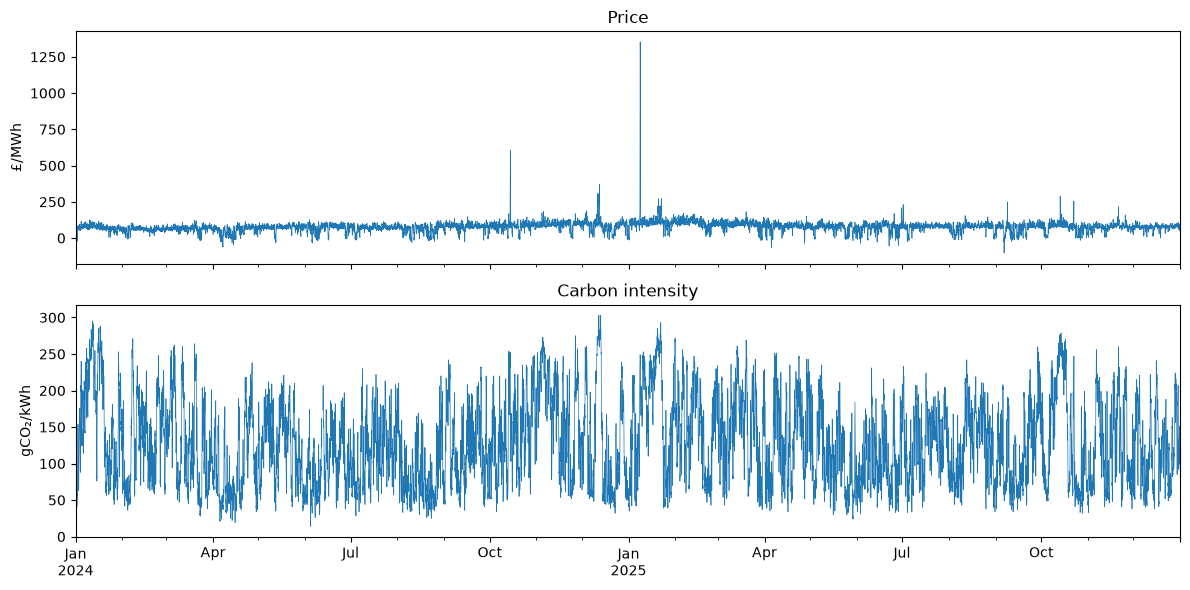

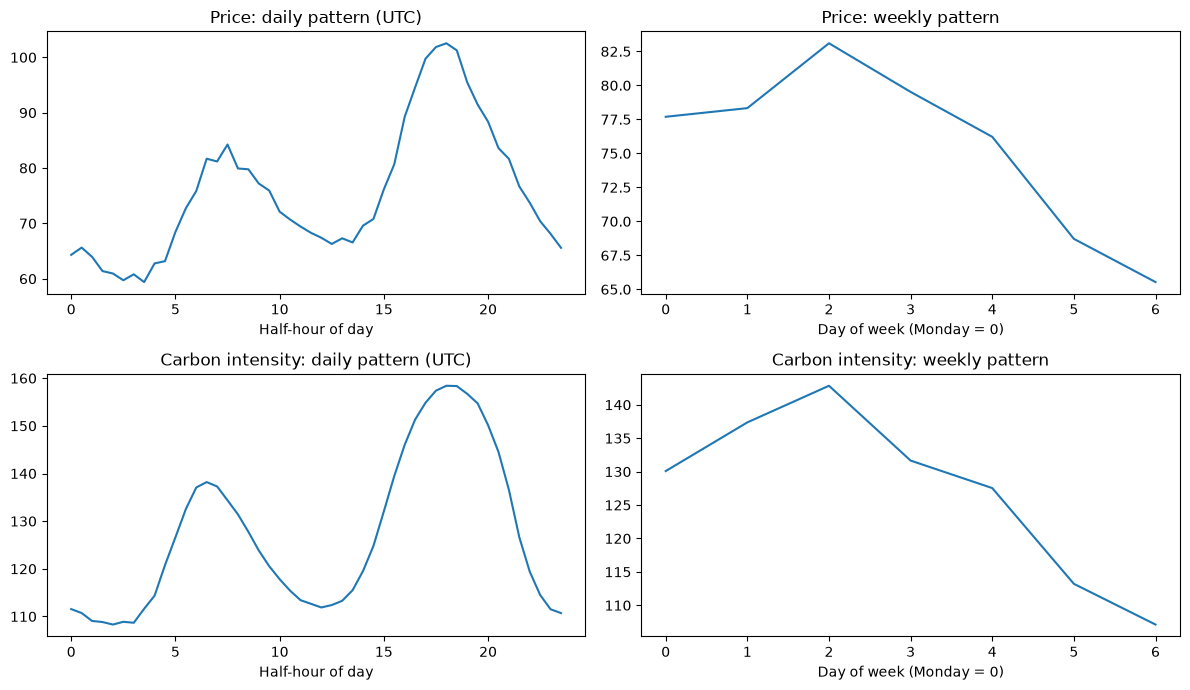

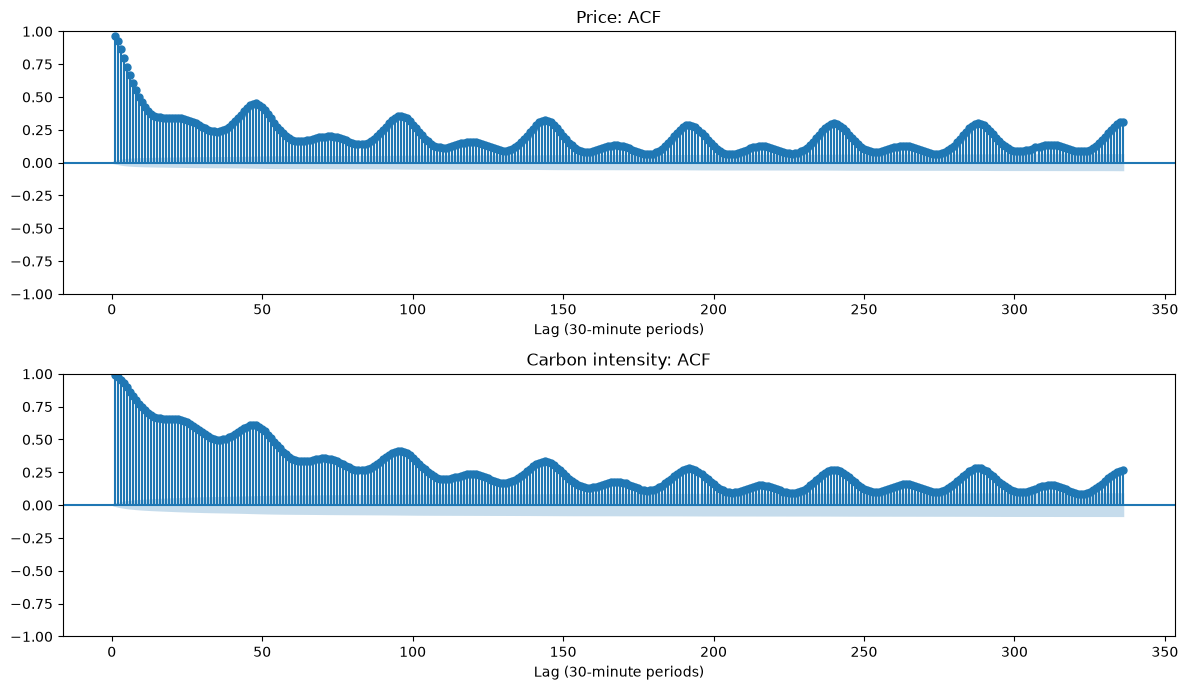

In [79]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# 1. Prepare time series
price = (
    datasets["electricity_price"]
    .set_index("startTime")["price"]
    .sort_index()
)

carbon = (
    datasets["carbon_intensity"]
    .set_index("from")["carbon_actual_gco2_kwh"]
    .sort_index()
)

assert price.index.equals(carbon.index), "Timestamps do not match."
assert price.index.is_unique
assert carbon.index.is_unique

print("Missing price observations:", price.isna().sum())
print("Missing carbon observations:", carbon.isna().sum())

targets = pd.DataFrame({"Price": price, "Carbon intensity": carbon})

print("Observations:", len(targets))
print("Missing values:\n", targets.isna().sum())

# 2. Time-series plots
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

for ax, column, unit in zip(
    axes, targets.columns, ["£/MWh", "gCO₂/kWh"]
):
    targets[column].plot(ax=ax, linewidth=0.5)
    ax.set(title=column, ylabel=unit)

plt.tight_layout()
plt.show()

# 3. Daily and weekly patterns (UTC)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for i, column in enumerate(targets.columns):
    series = targets[column]

    hour = series.index.hour + series.index.minute / 60
    series.groupby(hour).mean().plot(ax=axes[i, 0])

    series.groupby(
        series.index.dayofweek
    ).mean().plot(ax=axes[i, 1])

    axes[i, 0].set(
        title=f"{column}: daily pattern (UTC)",
        xlabel="Half-hour of day"
    )
    axes[i, 1].set(
        title=f"{column}: weekly pattern",
        xlabel="Day of week (Monday = 0)"
    )

plt.tight_layout()
plt.show()

# 4. Autocorrelation (up to 7 days)
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

for ax, column in zip(axes, targets.columns):
    plot_acf(
        targets[column],
        lags=336,
        missing="conservative",
        ax=ax,
        zero=False
    )
    ax.set(title=f"{column}: ACF", xlabel="Lag (30-minute periods)")

plt.tight_layout()
plt.show()

Pearson correlation:
                  Price  Carbon intensity
Price             1.000             0.583
Carbon intensity  0.583             1.000


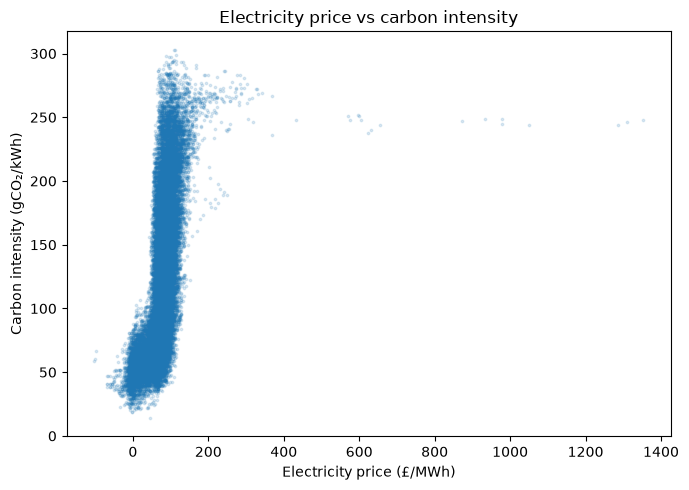

In [ ]:
# Price–carbon relationship
valid = targets.dropna()

print("Pearson correlation:")
print(valid.corr().round(3))

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    valid["Price"],
    valid["Carbon intensity"],
    s=3,
    alpha=0.15
)

ax.set(
    xlabel="Electricity price (£/MWh)",
    ylabel="Carbon intensity (gCO₂/kWh)",
    title="Electricity price vs carbon intensity"
)

plt.tight_layout()
plt.show()

In [ ]:
print("Pearson:", valid["Price"].corr(valid["Carbon intensity"]))
print("Spearman:", valid["Price"].corr(valid["Carbon intensity"], method="spearman"))

# Exclude extreme prices for a sensitivity check
threshold = valid["Price"].quantile(0.99)
regular = valid.loc[valid["Price"] <= threshold]

print("Pearson (≤99th percentile):",
      regular["Price"].corr(regular["Carbon intensity"]))

Pearson: 0.5827698271429352
Spearman: 0.6549742293049028
Pearson (≤99th percentile): 0.6321012965809123


      count   mean    std  median     min      max  negative_prices
2024  17568  71.38  31.19    73.9  -61.09   605.17              495
2025  17520  79.84  40.32    82.2 -102.92  1352.90              488


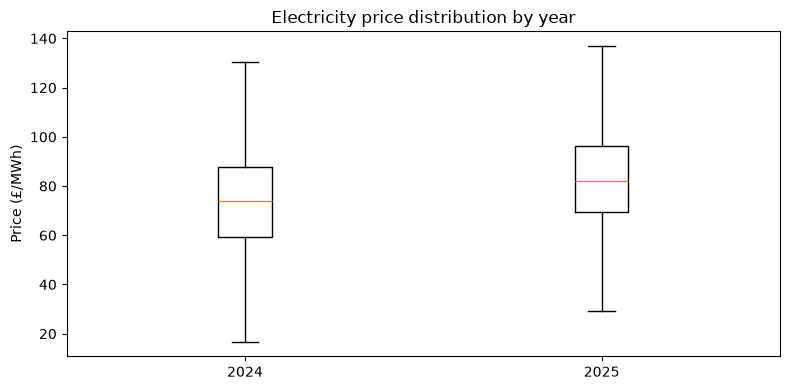

In [ ]:
#Annual electricity price distribution

price_by_year = targets["Price"].groupby(targets.index.year)

summary = price_by_year.agg(
    ["count", "mean", "std", "median", "min", "max"]
)
summary["negative_prices"] = price_by_year.apply(
    lambda x: (x < 0).sum()
)

print(summary.round(2))

fig, ax = plt.subplots(figsize=(8, 4))

ax.boxplot(
    [group.to_numpy() for _, group in price_by_year],
    tick_labels=[str(year) for year in price_by_year.groups],
    showfliers=False
)

ax.set(
    title="Electricity price distribution by year",
    ylabel="Price (£/MWh)"
)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Prepare targets
price_data = datasets["electricity_price"].set_index("startTime")
carbon_data = datasets["carbon_intensity"].set_index("from")

targets = pd.DataFrame({
    "price": price_data["price"].where(price_data["volume"] > 0),
    "carbon": carbon_data["carbon_actual_gco2_kwh"]
}).sort_index()

assert targets.index.is_unique
assert targets.index.equals(
    pd.date_range("2024-01-01", "2026-01-01",
                  freq="30min", tz="UTC", inclusive="left")
)

# Forecasts issued at 00:00 UTC on the preceding day
# Two-day and seven-day seasonal naive baselines
baselines = pd.DataFrame(index=targets.index)

for target in targets.columns:
    baselines[f"{target}_2d"] = targets[target].shift(96)
    baselines[f"{target}_7d"] = targets[target].shift(336)

# Validation only; reserve July–December 2025 for final testing
validation = (targets.index >= "2025-04-01") & (
    targets.index < "2025-07-01"
)

results = []

for target in targets.columns:
    for lag in ["2d", "7d"]:
        actual = targets.loc[validation, target]
        predicted = baselines.loc[validation, f"{target}_{lag}"]

        valid = actual.notna() & predicted.notna()
        error = actual[valid] - predicted[valid]

        results.append({
            "target": target,
            "baseline": lag,
            "observations": valid.sum(),
            "MAE": error.abs().mean(),
            "RMSE": np.sqrt((error ** 2).mean())
        })

baseline_results = pd.DataFrame(results)
print(baseline_results.round(3).to_string(index=False))

target baseline  observations    MAE   RMSE
 price       2d          4351 29.267 41.471
 price       7d          4358 26.952 38.019
carbon       2d          4368 45.526 57.626
carbon       7d          4368 45.056 57.345


In [ ]:
results = []

for target in targets.columns:
    actual = targets.loc[validation, target]
    pred_2d = baselines.loc[validation, f"{target}_2d"]
    pred_7d = baselines.loc[validation, f"{target}_7d"]

    valid = actual.notna() & pred_2d.notna() & pred_7d.notna()

    for name, pred in [("2d", pred_2d), ("7d", pred_7d)]:
        error = actual[valid] - pred[valid]

        results.append({
            "target": target,
            "baseline": name,
            "n": valid.sum(),
            "MAE": error.abs().mean(),
            "RMSE": np.sqrt(error.pow(2).mean())
        })

paired_results = pd.DataFrame(results)
print(paired_results.round(3).to_string(index=False))

target baseline    n    MAE   RMSE
 price       2d 4351 29.267 41.471
 price       7d 4351 26.895 37.928
carbon       2d 4368 45.526 57.626
carbon       7d 4368 45.056 57.345


In [43]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Historical features available before the scheduling decision
features = pd.DataFrame(index=targets.index)

for target in targets.columns:
    for lag in [144, 192, 336, 384]:
        features[f"{target}_lag_{lag}"] = targets[target].shift(lag)

hour = targets.index.hour + targets.index.minute / 60
weekday = targets.index.dayofweek
day_of_year = targets.index.dayofyear

for name, values, period in [
    ("hour", hour, 24),
    ("weekday", weekday, 7),
    ("year", day_of_year, 365.25)
]:
    features[f"{name}_sin"] = np.sin(2 * np.pi * values / period)
    features[f"{name}_cos"] = np.cos(2 * np.pi * values / period)

train = targets.index < "2025-03-30"

results = []

for target in targets.columns:
    data = features.copy()
    data["actual"] = targets[target]
    data["baseline"] = baselines[f"{target}_7d"]

    train_data = data.loc[train].dropna()
    val_data = data.loc[validation].dropna()

    X_train = train_data[features.columns]
    X_val = val_data[features.columns]

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(X_train, train_data["actual"])
    predicted = model.predict(X_val)

    actual = val_data["actual"].to_numpy()
    baseline = val_data["baseline"].to_numpy()

    for name, forecast in [
        ("7-day naive", baseline),
        ("Ridge", predicted)
    ]:
        error = actual - forecast

        results.append({
            "target": target,
            "model": name,
            "n": len(error),
            "MAE": np.mean(np.abs(error)),
            "RMSE": np.sqrt(np.mean(error ** 2))
        })

ridge_results = pd.DataFrame(results)
print(ridge_results.round(3).to_string(index=False))

target       model    n    MAE   RMSE
 price 7-day naive 4355 26.923 37.989
 price       Ridge 4355 23.001 30.268
carbon 7-day naive 4365 45.055 57.350
carbon       Ridge 4365 36.560 44.412


In [44]:
# Check availability of complete daily forecast windows
val = targets.loc[validation]

available_features = features.loc[validation].notna().all(axis=1)

coverage = pd.DataFrame(index=val.index)

for target in targets.columns:
    coverage[target] = (
        available_features
        & val[target].notna()
        & baselines.loc[validation, f"{target}_7d"].notna()
    )

daily_coverage = coverage.groupby(coverage.index.floor("D")).sum()

print("Validation days:", len(daily_coverage))
print("\nComplete 48-period days:")
print(daily_coverage.eq(48).sum())

print("\nDays with missing observations:")
print(daily_coverage.loc[daily_coverage.lt(48).any(axis=1)])

Validation days: 91

Complete 48-period days:
price     87
carbon    90
dtype: int64

Days with missing observations:
                           price  carbon
2025-06-27 00:00:00+00:00     45      48
2025-06-28 00:00:00+00:00     44      48
2025-06-29 00:00:00+00:00     45      48
2025-06-30 00:00:00+00:00     45      45


In [45]:
# Identify why validation observations are unavailable
for target in targets.columns:
    print(f"\n{target.upper()}")

    columns = features.columns.tolist()

    audit = features.loc[validation].copy()
    audit["actual"] = targets.loc[validation, target]
    audit["baseline"] = baselines.loc[
        validation, f"{target}_7d"
    ]

    missing = audit.isna().sum()
    print(missing[missing > 0].sort_values(ascending=False))


PRICE
actual           10
price_lag_144     3
dtype: int64

CARBON
price_lag_144    3
dtype: int64


In [46]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

train_mask = targets.index < "2025-03-30"
val_mask = (targets.index >= "2025-04-01") & (
    targets.index < "2025-07-01"
)

results = []

for target in ["price", "carbon"]:
    own_cols = [
        col for col in features.columns
        if col.startswith(f"{target}_lag_")
        or col.startswith(("hour_", "weekday_", "year_"))
    ]

    all_cols = features.columns.tolist()

    data = features.copy()
    data["actual"] = targets[target]

    train_data = data.loc[train_mask].dropna(
        subset=all_cols + ["actual"]
    )
    val_data = data.loc[val_mask].dropna(
        subset=all_cols + ["actual"]
    )

    for name, cols in [
        ("Own lags", own_cols),
        ("All lags", all_cols)
    ]:
        model = make_pipeline(
            StandardScaler(),
            Ridge(alpha=10.0)
        )

        model.fit(train_data[cols], train_data["actual"])
        predicted = model.predict(val_data[cols])

        error = val_data["actual"].to_numpy() - predicted

        results.append({
            "target": target,
            "features": name,
            "n": len(error),
            "MAE": np.mean(np.abs(error)),
            "RMSE": np.sqrt(np.mean(error ** 2))
        })

ablation_results = pd.DataFrame(results)
print(ablation_results.round(3).to_string(index=False))

target features    n    MAE   RMSE
 price Own lags 4355 22.925 30.184
 price All lags 4355 23.001 30.268
carbon Own lags 4365 36.657 44.740
carbon All lags 4365 36.560 44.412


In [47]:
results = []

for target in ["price", "carbon"]:
    own_cols = [
        c for c in features.columns
        if c.startswith(f"{target}_lag_")
        or c.startswith(("hour_", "weekday_", "year_"))
    ]

    for name, cols in [
        ("Own lags", own_cols),
        ("All lags", features.columns.tolist())
    ]:
        data = features[cols].copy()
        data["actual"] = targets[target]

        train_data = data.loc[train_mask].dropna()
        val_features = data.loc[val_mask, cols]
        valid = val_features.notna().all(axis=1)

        model = make_pipeline(
            StandardScaler(),
            Ridge(alpha=10.0)
        )
        model.fit(train_data[cols], train_data["actual"])

        predictions = pd.Series(
            model.predict(val_features.loc[valid]),
            index=val_features.index[valid]
        )

        actual = targets.loc[predictions.index, target]
        evaluable = actual.notna()
        error = actual[evaluable] - predictions[evaluable]

        results.append({
            "target": target,
            "features": name,
            "forecasts": len(predictions),
            "evaluated": len(error),
            "MAE": error.abs().mean(),
            "RMSE": np.sqrt(error.pow(2).mean())
        })

coverage_results = pd.DataFrame(results)
print(coverage_results.round(3).to_string(index=False))

target features  forecasts  evaluated    MAE   RMSE
 price Own lags       4365       4355 22.856 30.132
 price All lags       4365       4355 23.001 30.268
carbon Own lags       4368       4368 36.645 44.731
carbon All lags       4365       4365 36.560 44.412


In [50]:
# Ridge regularisation tuning

alphas = [0.1, 1, 10, 100, 1000]
results = []

for target in ["price", "carbon"]:
    cols = [
        c for c in features.columns
        if c.startswith(f"{target}_lag_")
        or c.startswith(("hour_", "weekday_", "year_"))
    ]

    X = features[cols]
    y = targets[target]

    train_valid = train_mask & X.notna().all(axis=1) & y.notna()
    val_valid = val_mask & X.notna().all(axis=1) & y.notna()

    X_train, y_train = X.loc[train_valid], y.loc[train_valid]
    X_val, y_val = X.loc[val_valid], y.loc[val_valid]

    for alpha in alphas:
        model = make_pipeline(
            StandardScaler(),
            Ridge(alpha=alpha)
        )

        model.fit(X_train, y_train)
        pred = model.predict(X_val)
        error = y_val.to_numpy() - pred

        results.append({
            "target": target,
            "alpha": alpha,
            "n": len(error),
            "MAE": np.mean(np.abs(error)),
            "RMSE": np.sqrt(np.mean(error ** 2))
        })

tuning_results = pd.DataFrame(results)

print(tuning_results.round(3).to_string(index=False))
print("\nBest alpha by validation MAE:")
print(
    tuning_results.loc[
        tuning_results.groupby("target")["MAE"].idxmin()
    ].to_string(index=False)
)

target  alpha    n    MAE   RMSE
 price    0.1 4355 22.857 30.132
 price    1.0 4355 22.856 30.132
 price   10.0 4355 22.856 30.132
 price  100.0 4355 22.847 30.129
 price 1000.0 4355 22.764 30.108
carbon    0.1 4368 36.645 44.732
carbon    1.0 4368 36.645 44.732
carbon   10.0 4368 36.645 44.731
carbon  100.0 4368 36.651 44.727
carbon 1000.0 4368 36.718 44.698

Best alpha by validation MAE:
target  alpha    n       MAE      RMSE
carbon    0.1 4368 36.644640 44.731756
 price 1000.0 4355 22.764328 30.108269


In [51]:
# Extended Ridge tuning (price only)

price_cols = [
    c for c in features.columns
    if c.startswith("price_lag_")
    or c.startswith(("hour_", "weekday_", "year_"))
]

X = features[price_cols]
y = targets["price"]

train_valid = train_mask & X.notna().all(axis=1) & y.notna()
val_valid = val_mask & X.notna().all(axis=1) & y.notna()

X_train, y_train = X.loc[train_valid], y.loc[train_valid]
X_val, y_val = X.loc[val_valid], y.loc[val_valid]

results = []

for alpha in [1000, 3000, 10000, 30000]:
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )
    model.fit(X_train, y_train)

    error = y_val.to_numpy() - model.predict(X_val)

    results.append({
        "alpha": alpha,
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2))
    })

print(pd.DataFrame(results).round(3).to_string(index=False))

 alpha    MAE   RMSE
  1000 22.764 30.108
  3000 22.615 30.084
 10000 22.292 30.133
 30000 21.976 30.540


In [52]:
# Calendar vs autoregressive features

calendar_cols = [
    c for c in features.columns
    if c.startswith(("hour_", "weekday_", "year_"))
]

price_cols = [
    c for c in features.columns
    if c.startswith("price_lag_")
]

cols = calendar_cols + price_cols
X = features[cols]
y = targets["price"]

train_valid = train_mask & X.notna().all(axis=1) & y.notna()
val_valid = val_mask & X.notna().all(axis=1) & y.notna()

results = []

for name, selected, alpha in [
    ("Calendar only", calendar_cols, 3000),
    ("Calendar + lags", cols, 3000),
    ("Calendar + lags", cols, 30000)
]:
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    model.fit(X.loc[train_valid, selected], y.loc[train_valid])

    actual = y.loc[val_valid].to_numpy()
    predicted = model.predict(X.loc[val_valid, selected])
    error = actual - predicted

    results.append({
        "model": name,
        "alpha": alpha,
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2))
    })

print(pd.DataFrame(results).round(3).to_string(index=False))

          model  alpha    MAE   RMSE
  Calendar only   3000 25.577 32.856
Calendar + lags   3000 22.615 30.084
Calendar + lags  30000 21.976 30.540


In [53]:
from sklearn.ensemble import HistGradientBoostingRegressor

results = []

for target in ["price", "carbon"]:
    cols = [
        c for c in features.columns
        if c.startswith(f"{target}_lag_")
        or c.startswith(("hour_", "weekday_", "year_"))
    ]

    X = features[cols]
    y = targets[target]

    train_valid = train_mask & X.notna().all(axis=1) & y.notna()
    val_valid = val_mask & X.notna().all(axis=1) & y.notna()

    X_train, y_train = X.loc[train_valid], y.loc[train_valid]
    X_val, y_val = X.loc[val_valid], y.loc[val_valid]

    models = {
        "Ridge": make_pipeline(
            StandardScaler(),
            Ridge(alpha=30000 if target == "price" else 0.1)
        ),
        "Gradient Boosting": HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=10,
            early_stopping=False,
            random_state=42
        )
    }

    for name, model in models.items():
        model.fit(X_train, y_train)
        error = y_val.to_numpy() - model.predict(X_val)

        results.append({
            "target": target,
            "model": name,
            "n": len(error),
            "MAE": np.abs(error).mean(),
            "RMSE": np.sqrt(np.mean(error ** 2))
        })

comparison_results = pd.DataFrame(results)
print(comparison_results.round(3).to_string(index=False))

target             model    n    MAE   RMSE
 price             Ridge 4355 21.976 30.540
 price Gradient Boosting 4355 22.060 30.658
carbon             Ridge 4368 36.645 44.732
carbon Gradient Boosting 4368 38.156 47.874


In [54]:
# 03.13 — Monthly forecasting performance

results = []

for target in ["price", "carbon"]:
    cols = [
        c for c in features.columns
        if c.startswith(f"{target}_lag_")
        or c.startswith(("hour_", "weekday_", "year_"))
    ]

    X = features[cols]
    y = targets[target]

    train_valid = train_mask & X.notna().all(axis=1) & y.notna()
    val_valid = val_mask & X.notna().all(axis=1) & y.notna()

    models = {
        "Ridge": make_pipeline(
            StandardScaler(),
            Ridge(alpha=30000 if target == "price" else 0.1)
        ),
        "Gradient Boosting": HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=10,
            early_stopping=False,
            random_state=42
        )
    }

    for name, model in models.items():
        model.fit(X.loc[train_valid], y.loc[train_valid])

        actual = y.loc[val_valid]
        predicted = pd.Series(
            model.predict(X.loc[val_valid]),
            index=actual.index
        )

        errors = (actual - predicted).abs()

        for month, group in errors.groupby(
            errors.index.to_period("M")
        ):
            results.append({
                "target": target,
                "month": str(month),
                "model": name,
                "n": len(group),
                "MAE": group.mean()
            })

monthly_results = pd.DataFrame(results)

print(
    monthly_results.pivot(
        index=["target", "month"],
        columns="model",
        values="MAE"
    ).round(3)
)

C:\Users\Serface\AppData\Local\Temp\ipykernel_15732\1368554932.py:45: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  errors.index.to_period("M")
C:\Users\Serface\AppData\Local\Temp\ipykernel_15732\1368554932.py:45: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  errors.index.to_period("M")
C:\Users\Serface\AppData\Local\Temp\ipykernel_15732\1368554932.py:45: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  errors.index.to_period("M")


model           Gradient Boosting   Ridge
target month                             
carbon 2025-04             47.605  44.647
       2025-05             37.192  33.512
       2025-06             29.702  31.879
price  2025-04             17.950  16.923
       2025-05             20.048  20.065
       2025-06             28.305  29.069


C:\Users\Serface\AppData\Local\Temp\ipykernel_15732\1368554932.py:45: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  errors.index.to_period("M")


In [55]:
results = []

for target in ["price", "carbon"]:
    cols = [
        c for c in features.columns
        if c.startswith(f"{target}_lag_")
        or c.startswith(("hour_", "weekday_", "year_"))
    ]

    X = features[cols]
    y = targets[target]

    train_valid = train_mask & X.notna().all(axis=1) & y.notna()
    val_valid = val_mask & X.notna().all(axis=1) & y.notna()

    models = {
        "Ridge": make_pipeline(
            StandardScaler(),
            Ridge(alpha=30000 if target == "price" else 0.1)
        ),
        "Gradient Boosting": HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=10,
            early_stopping=False,
            random_state=42
        )
    }

    for name, model in models.items():
        model.fit(X.loc[train_valid], y.loc[train_valid])

        actual = y.loc[val_valid]
        predicted = model.predict(X.loc[val_valid])
        errors = np.abs(actual.to_numpy() - predicted)

        # Hours since the previous day's 00:00 UTC
        horizon = (
            24 + actual.index.hour
            + actual.index.minute / 60
        )

        bands = pd.cut(
            horizon,
            bins=[24, 30, 36, 42, 48],
            labels=["24–30h", "30–36h", "36–42h", "42–48h"],
            right=False
        )

        for band in bands.categories:
            mask = bands == band

            results.append({
                "target": target,
                "model": name,
                "horizon": band,
                "n": mask.sum(),
                "MAE": errors[mask].mean()
            })

horizon_results = pd.DataFrame(results)

print(
    horizon_results.pivot(
        index=["target", "horizon"],
        columns="model",
        values="MAE"
    ).round(3)
)

model           Gradient Boosting   Ridge
target horizon                           
carbon 24–30h              38.917  37.629
       30–36h              33.855  33.637
       36–42h              36.488  34.897
       42–48h              43.363  40.415
price  24–30h              21.181  20.068
       30–36h              26.182  27.434
       36–42h              25.429  24.465
       42–48h              15.444  15.941


In [56]:
# Price forecasting under extreme conditions

cols = [
    c for c in features.columns
    if c.startswith("price_lag_")
    or c.startswith(("hour_", "weekday_", "year_"))
]

X = features[cols]
y = targets["price"]

train_valid = train_mask & X.notna().all(axis=1) & y.notna()

val_valid = (
    val_mask
    & X.notna().all(axis=1)
    & y.notna()
    & baselines["price_7d"].notna()
)

X_train, y_train = X.loc[train_valid], y.loc[train_valid]
X_val, y_val = X.loc[val_valid], y.loc[val_valid]

models = {
    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=30000)
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=10,
        early_stopping=False,
        random_state=42
    )
}

predictions = {
    "7-day naive": baselines.loc[val_valid, "price_7d"].to_numpy()
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_val)

threshold = y_train.quantile(0.95)
extreme = y_val.to_numpy() > threshold

results = []

for name, pred in predictions.items():
    errors = np.abs(y_val.to_numpy() - pred)

    for group, mask in [
        ("All periods", np.ones(len(y_val), dtype=bool)),
        ("High-price periods", extreme),
        ("Other periods", ~extreme)
    ]:
        results.append({
            "model": name,
            "group": group,
            "n": mask.sum(),
            "MAE": errors[mask].mean(),
            "RMSE": np.sqrt(np.mean(errors[mask] ** 2))
        })

print("Training 95th-percentile threshold:", round(threshold, 2))
print(pd.DataFrame(results).round(3).to_string(index=False))

Training 95th-percentile threshold: 123.34
            model              group    n    MAE   RMSE
      7-day naive        All periods 4355 26.923 37.989
      7-day naive High-price periods   54 43.071 53.128
      7-day naive      Other periods 4301 26.720 37.761
            Ridge        All periods 4355 21.976 30.540
            Ridge High-price periods   54 59.099 63.043
            Ridge      Other periods 4301 21.510 29.908
Gradient Boosting        All periods 4355 22.060 30.658
Gradient Boosting High-price periods   54 45.750 51.759
Gradient Boosting      Other periods 4301 21.762 30.300


In [57]:
# High-price forecast bias

actual = y_val.to_numpy()
results = []

for name, pred in predictions.items():
    error = actual[extreme] - pred[extreme]

    results.append({
        "model": name,
        "actual_mean": actual[extreme].mean(),
        "forecast_mean": pred[extreme].mean(),
        "bias": error.mean(),
        "underprediction_rate": (error > 0).mean()
    })

print(pd.DataFrame(results).round(3).to_string(index=False))

            model  actual_mean  forecast_mean   bias  underprediction_rate
      7-day naive       139.97         98.163 41.807                 0.963
            Ridge       139.97         80.871 59.099                 1.000
Gradient Boosting       139.97         94.220 45.750                 1.000


In [58]:
#  Daily price ranking accuracy

daily_results = []

for name, forecast in predictions.items():
    df = pd.DataFrame({
        "actual": y_val.to_numpy(),
        "forecast": forecast
    }, index=y_val.index)

    for day, group in df.groupby(df.index.floor("D")):
        if len(group) != 48 or group.isna().any().any():
            continue

        daily_results.append({
            "model": name,
            "date": day,
            "spearman": group["actual"].corr(
                group["forecast"], method="spearman"
            )
        })

ranking_results = pd.DataFrame(daily_results)

print(
    ranking_results.groupby("model")["spearman"]
    .agg(["count", "mean", "median"])
    .round(3)
)

                   count   mean  median
model                                  
7-day naive           87  0.505   0.518
Gradient Boosting     87  0.622   0.651
Ridge                 87  0.545   0.602


In [59]:
# 03.18 — Preliminary cost-based scheduling backtest

daily_costs = []
energy_per_slot = 0.5  # MWh
slots_required = 12

forecast_df = pd.DataFrame(predictions, index=y_val.index)
forecast_df["actual"] = y_val

for day, group in forecast_df.groupby(forecast_df.index.floor("D")):
    if len(group) != 48 or group.isna().any().any():
        continue

    actual = group["actual"].to_numpy()

    schedules = {
        "Fixed": np.arange(slots_required),
        "Oracle": np.argsort(actual)[:slots_required]
    }

    for model in predictions:
        schedules[model] = np.argsort(
            group[model].to_numpy()
        )[:slots_required]

    for policy, selected in schedules.items():
        daily_costs.append({
            "date": day,
            "policy": policy,
            "cost_gbp": actual[selected].sum() * energy_per_slot
        })

cost_results = pd.DataFrame(daily_costs)

summary = cost_results.groupby("policy")["cost_gbp"].agg(
    ["count", "mean", "sum"]
)

fixed_cost = summary.loc["Fixed", "sum"]

summary["saving_vs_fixed_pct"] = (
    100 * (fixed_cost - summary["sum"]) / fixed_cost
)

print(summary.round(3))

                   count     mean        sum  saving_vs_fixed_pct
policy                                                           
7-day naive           87  347.992  30275.320               15.862
Fixed                 87  413.596  35982.880                0.000
Gradient Boosting     87  333.636  29026.305               19.333
Oracle                87  270.720  23552.610               34.545
Ridge                 87  356.513  31016.620               13.802


In [60]:
# 03.19 — Realised cost and carbon emissions

evaluation = forecast_df.join(
    targets["carbon"].rename("carbon")
)

results = []
energy_per_slot = 0.5
slots_required = 12

for day, group in evaluation.groupby(evaluation.index.floor("D")):
    if len(group) != 48 or group.isna().any().any():
        continue

    actual_price = group["actual"].to_numpy()
    actual_carbon = group["carbon"].to_numpy()

    schedules = {
        "Fixed": np.arange(slots_required),
        "7-day naive": np.argsort(group["7-day naive"].to_numpy())[:slots_required],
        "Ridge": np.argsort(group["Ridge"].to_numpy())[:slots_required],
        "Gradient Boosting": np.argsort(
            group["Gradient Boosting"].to_numpy()
        )[:slots_required],
        "Cost oracle": np.argsort(actual_price)[:slots_required]
    }

    for policy, slots in schedules.items():
        results.append({
            "date": day,
            "policy": policy,
            "cost_gbp": actual_price[slots].sum() * energy_per_slot,
            "carbon_kg": actual_carbon[slots].sum() * energy_per_slot
        })

impact = pd.DataFrame(results)

summary = impact.groupby("policy").agg(
    days=("date", "nunique"),
    cost_gbp=("cost_gbp", "sum"),
    carbon_kg=("carbon_kg", "sum")
)

fixed = summary.loc["Fixed"]

summary["cost_saving_pct"] = (
    1 - summary["cost_gbp"] / fixed["cost_gbp"]
) * 100

summary["carbon_reduction_pct"] = (
    1 - summary["carbon_kg"] / fixed["carbon_kg"]
) * 100

print(summary.round(3).to_string())

                   days   cost_gbp  carbon_kg  cost_saving_pct  carbon_reduction_pct
policy                                                                              
7-day naive          87  30275.320    49615.0           15.862                17.469
Cost oracle          87  23552.610    45191.5           34.545                24.827
Fixed                87  35982.880    60116.5            0.000                 0.000
Gradient Boosting    87  29026.305    48730.5           19.333                18.940
Ridge                87  31016.620    50200.5           13.802                16.495


In [61]:
# 04.1 — Carbon forecasts for scheduling

carbon_cols = [
    c for c in features.columns
    if c.startswith("carbon_lag_")
    or c.startswith(("hour_", "weekday_", "year_"))
]

X = features[carbon_cols]
y = targets["carbon"]

train_valid = train_mask & X.notna().all(axis=1) & y.notna()
val_features = X.loc[val_mask]
available = val_features.notna().all(axis=1)

carbon_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=0.1)
)

carbon_model.fit(X.loc[train_valid], y.loc[train_valid])

carbon_forecasts = pd.Series(
    carbon_model.predict(val_features.loc[available]),
    index=val_features.index[available],
    name="carbon_forecast"
)

# Align with existing price forecasts and realised outcomes
scheduling_data = forecast_df.join(carbon_forecasts)
scheduling_data = scheduling_data.join(
    targets["carbon"].rename("carbon_actual")
)

print("Rows:", len(scheduling_data))
print("\nMissing values:")
print(scheduling_data.isna().sum())

print("\nComplete scheduling days:")
complete_days = scheduling_data.groupby(
    scheduling_data.index.floor("D")
).apply(
    lambda df: len(df) == 48 and df.notna().all().all()
)
print(complete_days.sum())

Rows: 4355

Missing values:
7-day naive          0
Ridge                0
Gradient Boosting    0
actual               0
carbon_forecast      0
carbon_actual        0
dtype: int64

Complete scheduling days:
87


In [62]:
import numpy as np
import pandas as pd
from scipy.optimize import linprog

ENERGY_MWH = 6.0
MAX_SLOT_MWH = 0.5

def optimise(price, carbon=None, carbon_budget=None):
    n = len(price)
    constraints = (
        None if carbon_budget is None
        else np.asarray(carbon).reshape(1, -1)
    )

    result = linprog(
        c=price,
        A_ub=constraints,
        b_ub=None if carbon_budget is None else [carbon_budget],
        A_eq=np.ones((1, n)),
        b_eq=[ENERGY_MWH],
        bounds=(0, MAX_SLOT_MWH),
        method="highs"
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result.x


records = []

for day, group in scheduling_data.groupby(
    scheduling_data.index.floor("D")
):
    if len(group) != 48 or not np.isfinite(group.to_numpy()).all():
        continue

    actual_price = group["actual"].to_numpy()
    actual_carbon = group["carbon_actual"].to_numpy()
    predicted_carbon = group["carbon_forecast"].to_numpy()
    predicted_price = group["Gradient Boosting"].to_numpy()

    cost_only = optimise(predicted_price)
    carbon_only = optimise(predicted_carbon)

    carbon_min = predicted_carbon @ carbon_only
    carbon_cost = predicted_carbon @ cost_only

    schedules = {
        "Fixed": np.r_[np.full(12, 0.5), np.zeros(36)],
        "Cost only": cost_only,
        "Carbon only": carbon_only
    }

    for reduction in [0.25, 0.50, 0.75]:
        budget = carbon_cost - reduction * (carbon_cost - carbon_min)

        schedules[f"Carbon constraint {int(reduction * 100)}%"] = (
            optimise(
                predicted_price,
                predicted_carbon,
                budget + 1e-7
            )
        )

    for policy, x in schedules.items():
        records.append({
            "date": day,
            "policy": policy,
            "cost_gbp": actual_price @ x,
            "carbon_kg": actual_carbon @ x
        })

lp_results = pd.DataFrame(records)

summary = lp_results.groupby("policy").agg(
    days=("date", "nunique"),
    cost_gbp=("cost_gbp", "sum"),
    carbon_kg=("carbon_kg", "sum")
)

fixed = summary.loc["Fixed"]

summary["cost_saving_pct"] = (
    1 - summary["cost_gbp"] / fixed["cost_gbp"]
) * 100

summary["carbon_reduction_pct"] = (
    1 - summary["carbon_kg"] / fixed["carbon_kg"]
) * 100

print(summary.round(3).to_string())

                       days   cost_gbp  carbon_kg  cost_saving_pct  carbon_reduction_pct
policy                                                                                  
Carbon constraint 25%    87  29195.709  48472.358           18.862                19.369
Carbon constraint 50%    87  29467.527  48296.700           18.107                19.661
Carbon constraint 75%    87  29866.501  48131.365           16.998                19.937
Carbon only              87  31390.640  48996.500           12.762                18.497
Cost only                87  29021.610  48730.500           19.346                18.940
Fixed                    87  35982.880  60116.500            0.000                 0.000


In [63]:
# 04.3 — Predicted vs realised carbon performance

records = []

for day, group in scheduling_data.groupby(
    scheduling_data.index.floor("D")
):
    if len(group) != 48 or group.isna().any().any():
        continue

    p = group["Gradient Boosting"].to_numpy()
    c = group["carbon_forecast"].to_numpy()
    actual_c = group["carbon_actual"].to_numpy()

    schedules = {
        "Cost only": optimise(p),
        "Carbon only": optimise(c)
    }

    for policy, x in schedules.items():
        records.append({
            "date": day,
            "policy": policy,
            "predicted_kg": c @ x,
            "realised_kg": actual_c @ x
        })

carbon_check = pd.DataFrame(records)

comparison = carbon_check.pivot(
    index="date",
    columns="policy",
    values=["predicted_kg", "realised_kg"]
)

predicted_diff = (
    comparison["predicted_kg"]["Carbon only"]
    - comparison["predicted_kg"]["Cost only"]
)

realised_diff = (
    comparison["realised_kg"]["Carbon only"]
    - comparison["realised_kg"]["Cost only"]
)

print("Days evaluated:", len(comparison))
print("Predicted carbon optimisation violations:",
      (predicted_diff > 1e-6).sum())
print("Days carbon-only performs worse in reality:",
      (realised_diff > 0).sum())

print("\nTotal predicted carbon difference (kg):",
      round(predicted_diff.sum(), 2))
print("Total realised carbon difference (kg):",
      round(realised_diff.sum(), 2))

Days evaluated: 87
Predicted carbon optimisation violations: 0
Days carbon-only performs worse in reality: 44

Total predicted carbon difference (kg): -1699.71
Total realised carbon difference (kg): 266.0


In [64]:
# 04.4 — Daily paired bootstrap (validation only)

rng = np.random.default_rng(42)
n_boot = 10000

daily = lp_results.pivot(
    index="date",
    columns="policy",
    values=["cost_gbp", "carbon_kg"]
)

policies = [
    "Carbon only",
    "Carbon constraint 25%",
    "Carbon constraint 50%",
    "Carbon constraint 75%"
]

results = []

for policy in policies:
    for metric in ["cost_gbp", "carbon_kg"]:
        diff = (
            daily[metric][policy] - daily[metric]["Cost only"]
        ).to_numpy()

        samples = rng.choice(
            diff, size=(n_boot, len(diff)), replace=True
        ).mean(axis=1)

        lo, hi = np.percentile(samples, [2.5, 97.5])

        results.append({
            "policy": policy,
            "metric": metric,
            "mean_daily_diff": diff.mean(),
            "CI_low": lo,
            "CI_high": hi
        })

robustness = pd.DataFrame(results)
print(robustness.round(3).to_string(index=False))

               policy    metric  mean_daily_diff  CI_low  CI_high
          Carbon only  cost_gbp           27.230  14.854   40.490
          Carbon only carbon_kg            3.057 -15.157   22.012
Carbon constraint 25%  cost_gbp            2.001  -0.738    4.828
Carbon constraint 25% carbon_kg           -2.967  -7.698    1.569
Carbon constraint 50%  cost_gbp            5.125   0.340   10.180
Carbon constraint 50% carbon_kg           -4.986 -13.162    2.738
Carbon constraint 75%  cost_gbp            9.711   2.177   17.737
Carbon constraint 75% carbon_kg           -6.887 -18.732    4.979


In [65]:
# 04.5 — Scheduling baseline robustness

records = []

for day, group in scheduling_data.groupby(
    scheduling_data.index.floor("D")
):
    if len(group) != 48 or not np.isfinite(group.to_numpy()).all():
        continue

    actual_price = group["actual"].to_numpy()
    actual_carbon = group["carbon_actual"].to_numpy()
    predicted_price = group["Gradient Boosting"].to_numpy()

    schedules = {
        "Uniform": np.full(48, ENERGY_MWH / 48),
        "Fixed": np.r_[np.full(12, 0.5), np.zeros(36)],
        "Forecast-informed": optimise(predicted_price)
    }

    for policy, x in schedules.items():
        records.append({
            "date": day,
            "policy": policy,
            "cost_gbp": actual_price @ x,
            "carbon_kg": actual_carbon @ x
        })

baseline_robustness = pd.DataFrame(records)

summary = baseline_robustness.groupby("policy").agg(
    days=("date", "nunique"),
    cost_gbp=("cost_gbp", "sum"),
    carbon_kg=("carbon_kg", "sum")
)

for baseline in ["Uniform", "Fixed"]:
    summary[f"cost_saving_vs_{baseline.lower()}_%"] = (
        1 - summary["cost_gbp"] / summary.loc[baseline, "cost_gbp"]
    ) * 100

print(summary.round(3).to_string())

                   days  cost_gbp  carbon_kg  cost_saving_vs_uniform_%  cost_saving_vs_fixed_%
policy                                                                                        
Fixed                87  35982.88    60116.5                     3.921                   0.000
Forecast-informed    87  29021.61    48730.5                    22.509                  19.346
Uniform              87  37451.38    59201.5                     0.000                  -4.081


In [66]:
# 04.6 — Scheduling flexibility sensitivity

capacities = [0.25, 0.5, 0.75, 1.0, 1.5]
records = []

for day, group in scheduling_data.groupby(
    scheduling_data.index.floor("D")
):
    if len(group) != 48 or not np.isfinite(group.to_numpy()).all():
        continue

    actual_price = group["actual"].to_numpy()
    forecast_price = group["Gradient Boosting"].to_numpy()

    uniform = np.full(48, ENERGY_MWH / 48)
    uniform_cost = actual_price @ uniform

    for capacity in capacities:
        result = linprog(
            c=forecast_price,
            A_eq=np.ones((1, 48)),
            b_eq=[ENERGY_MWH],
            bounds=(0, capacity * 0.5),
            method="highs"
        )

        if not result.success:
            raise RuntimeError(result.message)

        records.append({
            "date": day,
            "capacity_mw": capacity,
            "uniform_cost": uniform_cost,
            "optimised_cost": actual_price @ result.x
        })

sensitivity = pd.DataFrame(records)

summary = sensitivity.groupby("capacity_mw").agg(
    days=("date", "nunique"),
    uniform_cost=("uniform_cost", "sum"),
    optimised_cost=("optimised_cost", "sum")
)

summary["saving_pct"] = 100 * (
    1 - summary["optimised_cost"] / summary["uniform_cost"]
)

print(summary.round(3).to_string())

             days  uniform_cost  optimised_cost  saving_pct
capacity_mw                                                
0.25           87      37451.38       37451.380       0.000
0.50           87      37451.38       31620.360      15.570
0.75           87      37451.38       30184.568      19.403
1.00           87      37451.38       29021.610      22.509
1.50           87      37451.38       27982.770      25.282


In [67]:
# 04.7 — Deadline sensitivity

deadlines = [12, 16, 20, 24]
records = []

for day, group in scheduling_data.groupby(
    scheduling_data.index.floor("D")
):
    if len(group) != 48 or not np.isfinite(group.to_numpy()).all():
        continue

    actual = group["actual"].to_numpy()
    forecast = group["Gradient Boosting"].to_numpy()

    for deadline in deadlines:
        available = 2 * deadline

        result = linprog(
            c=forecast[:available],
            A_eq=np.ones((1, available)),
            b_eq=[ENERGY_MWH],
            bounds=(0, MAX_SLOT_MWH),
            method="highs"
        )

        if not result.success:
            raise RuntimeError(result.message)

        schedule = result.x
        uniform = np.full(available, ENERGY_MWH / available)

        records.append({
            "date": day,
            "deadline_h": deadline,
            "uniform_cost": actual[:available] @ uniform,
            "optimised_cost": actual[:available] @ schedule
        })

deadline_results = pd.DataFrame(records)

summary = deadline_results.groupby("deadline_h").agg(
    days=("date", "nunique"),
    uniform_cost=("uniform_cost", "sum"),
    optimised_cost=("optimised_cost", "sum")
)

summary["saving_pct"] = 100 * (
    1 - summary["optimised_cost"] / summary["uniform_cost"]
)

print(summary.round(3).to_string())

            days  uniform_cost  optimised_cost  saving_pct
deadline_h                                                
12            87     35779.515        32677.55       8.670
16            87     33632.640        28778.93      14.432
20            87     36504.176        28778.93      21.163
24            87     37451.380        29021.61      22.509


In [68]:
# 04.8 — Daily savings consistency

daily = baseline_robustness.pivot(
    index="date",
    columns="policy",
    values="cost_gbp"
)

daily["saving_pct"] = 100 * (
    1 - daily["Forecast-informed"] / daily["Uniform"]
)

print("Days evaluated:", len(daily))
print("Days with positive savings:", (daily["saving_pct"] > 0).sum())
print("Days with negative savings:", (daily["saving_pct"] < 0).sum())

print("\nDaily savings distribution (%):")
print(
    daily["saving_pct"]
    .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
    .round(2)
)

print("\nAggregate savings (%):")
print(round(
    100 * (
        1 - daily["Forecast-informed"].sum()
        / daily["Uniform"].sum()
    ), 2
))

Days evaluated: 87
Days with positive savings: 83
Days with negative savings: 4

Daily savings distribution (%):
count     87.00
mean      33.53
std       49.95
min      -23.15
5%         0.99
25%        9.20
50%       15.78
75%       42.26
95%      109.74
max      344.72
Name: saving_pct, dtype: float64

Aggregate savings (%):
22.51


In [69]:
# 05.1 — Out-of-sample scheduling backtest

test_mask = (targets.index >= "2025-07-01") & (
    targets.index < "2026-01-01"
)
fit_mask = targets.index < "2025-06-30"

price_cols = [
    c for c in features.columns
    if c.startswith("price_lag_")
    or c.startswith(("hour_", "weekday_", "year_"))
]

X = features[price_cols]
y = targets["price"]

fit_valid = fit_mask & X.notna().all(axis=1) & y.notna()

models = {
    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=30000)
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=10,
        early_stopping=False,
        random_state=42
    )
}

test = targets.loc[test_mask].copy()
test["7-day naive"] = baselines.loc[test_mask, "price_7d"]

available = X.loc[test_mask].notna().all(axis=1)

for name, model in models.items():
    model.fit(X.loc[fit_valid], y.loc[fit_valid])
    test[name] = np.nan
    test.loc[available, name] = model.predict(
        X.loc[test_mask & X.notna().all(axis=1)]
    )

records = []

for day, group in test.groupby(test.index.floor("D")):
    if len(group) != 48 or group.isna().any().any():
        continue

    p = group["price"].to_numpy()
    c = group["carbon"].to_numpy()

    schedules = {
        "Uniform": np.full(48, 6 / 48),
        "Fixed": np.r_[np.full(12, 0.5), np.zeros(36)],
        "7-day naive": optimise(group["7-day naive"].to_numpy()),
        "Ridge": optimise(group["Ridge"].to_numpy()),
        "Gradient Boosting": optimise(
            group["Gradient Boosting"].to_numpy()
        ),
        "Oracle": optimise(p)
    }

    for policy, x in schedules.items():
        records.append({
            "date": day,
            "policy": policy,
            "cost_gbp": p @ x,
            "carbon_kg": c @ x
        })

test_results = pd.DataFrame(records)

summary = test_results.groupby("policy").agg(
    days=("date", "nunique"),
    cost_gbp=("cost_gbp", "sum"),
    carbon_kg=("carbon_kg", "sum")
)

baseline = summary.loc["Uniform"]

summary["cost_saving_pct"] = 100 * (
    1 - summary["cost_gbp"] / baseline["cost_gbp"]
)

summary["carbon_reduction_pct"] = 100 * (
    1 - summary["carbon_kg"] / baseline["carbon_kg"]
)

print("Test days:", test.index.normalize().nunique())
print("Complete evaluation days:", test_results["date"].nunique())
print(summary.round(3).to_string())

Test days: 184
Complete evaluation days: 172
                   days   cost_gbp  carbon_kg  cost_saving_pct  carbon_reduction_pct
policy                                                                              
7-day naive         172  64638.175  111065.50           15.323                15.049
Fixed               172  64494.500  117070.50           15.511                10.456
Gradient Boosting   172  60937.060  107367.00           20.172                17.878
Oracle              172  54685.040  105565.50           28.362                19.256
Ridge               172  62654.590  110749.50           17.922                15.291
Uniform             172  76335.186  130740.75            0.000                 0.000


In [70]:
# 05.2 — Test coverage audit

required = [
    "price", "carbon", "7-day naive",
    "Ridge", "Gradient Boosting"
]

audit = test[required].copy()
audit["date"] = audit.index.floor("D")

daily = audit.groupby("date").agg(
    rows=("price", "size"),
    **{
        f"missing_{col}": (col, lambda x: x.isna().sum())
        for col in required
    }
)

excluded = daily.loc[
    (daily["rows"] != 48)
    | daily.filter(like="missing_").gt(0).any(axis=1)
]

print("Total days:", len(daily))
print("Excluded days:", len(excluded))
print(excluded.to_string())

Total days: 184
Excluded days: 12
                           rows  missing_price  missing_carbon  missing_7-day naive  missing_Ridge  missing_Gradient Boosting
date                                                                                                                         
2025-07-01 00:00:00+00:00    48              0               0                    0              7                          7
2025-07-02 00:00:00+00:00    48              0               0                    0              7                          7
2025-07-03 00:00:00+00:00    48              0               0                    0              3                          3
2025-07-04 00:00:00+00:00    48              0               0                    3              3                          3
2025-07-05 00:00:00+00:00    48              0               0                    4              7                          7
2025-07-06 00:00:00+00:00    48              0               0                    3 

In [71]:
# 05.3 — Forecast availability with historical fallback

test_fallback = test.copy()

historical = targets["price"]

fallback = historical.shift(336)

for lag in [672, 1008]:
    fallback = fallback.fillna(historical.shift(lag))

for model in ["Ridge", "Gradient Boosting"]:
    test_fallback[model] = test_fallback[model].fillna(
        fallback.reindex(test_fallback.index)
    )

# Evaluate complete daily schedules
required = [
    "price", "carbon", "7-day naive",
    "Ridge", "Gradient Boosting"
]

coverage = test_fallback[required].copy()
coverage["7-day naive"] = coverage["7-day naive"].fillna(
    fallback.reindex(coverage.index)
)

complete = coverage.groupby(coverage.index.floor("D")).apply(
    lambda day: len(day) == 48 and day.notna().all().all()
)

print("Complete evaluation days:", complete.sum())
print("Excluded days:", (~complete).sum())
print("\nRemaining excluded dates:")
print(complete.index[~complete])

Complete evaluation days: 183
Excluded days: 1

Remaining excluded dates:
DatetimeIndex(['2025-09-06 00:00:00+00:00'], dtype='datetime64[us, UTC]', freq=None)


In [72]:
# 05.4 — Revised out-of-sample scheduling backtest

records = []

for day, group in coverage.groupby(coverage.index.floor("D")):
    if len(group) != 48 or group.isna().any().any():
        continue

    actual_price = group["price"].to_numpy()
    actual_carbon = group["carbon"].to_numpy()

    schedules = {
        "Uniform": np.full(48, ENERGY_MWH / 48),

        "Fixed": np.r_[
            np.full(12, MAX_SLOT_MWH),
            np.zeros(36)
        ],

        "7-day naive": optimise(
            group["7-day naive"].to_numpy()
        ),

        "Ridge": optimise(
            group["Ridge"].to_numpy()
        ),

        "Gradient Boosting": optimise(
            group["Gradient Boosting"].to_numpy()
        ),

        "Oracle": optimise(actual_price)
    }

    for policy, x in schedules.items():
        records.append({
            "date": day,
            "policy": policy,
            "cost_gbp": actual_price @ x,
            "carbon_kg": actual_carbon @ x
        })

revised_test_results = pd.DataFrame(records)

revised_summary = revised_test_results.groupby("policy").agg(
    days=("date", "nunique"),
    cost_gbp=("cost_gbp", "sum"),
    carbon_kg=("carbon_kg", "sum")
)

uniform = revised_summary.loc["Uniform"]

revised_summary["cost_saving_pct"] = 100 * (
    1 - revised_summary["cost_gbp"] / uniform["cost_gbp"]
)

revised_summary["carbon_reduction_pct"] = 100 * (
    1 - revised_summary["carbon_kg"] / uniform["carbon_kg"]
)

print(revised_summary.round(3).to_string())

                   days   cost_gbp  carbon_kg  cost_saving_pct  carbon_reduction_pct
policy                                                                              
7-day naive         183  67975.755  116858.50           15.840                15.072
Fixed               183  69032.790  124670.00           14.531                 9.395
Gradient Boosting   183  64341.355  113245.50           20.339                17.698
Oracle              183  57092.730  110814.50           29.314                19.465
Ridge               183  66011.090  116833.00           18.272                15.091
Uniform             183  80769.279  137597.75            0.000                 0.000


In [73]:
# 05.5 — Paired moving-block bootstrap

rng = np.random.default_rng(42)

daily = revised_test_results.pivot(
    index="date",
    columns="policy",
    values=["cost_gbp", "carbon_kg"]
).sort_index()

policies = [
    "Uniform",
    "7-day naive",
    "Ridge",
    "Gradient Boosting"
]

cost = daily["cost_gbp"][policies].to_numpy()
carbon = daily["carbon_kg"][policies].to_numpy()

n = len(daily)
block_length = 7
n_boot = 5000
n_blocks = int(np.ceil(n / block_length))

# Circular moving-block bootstrap
starts = rng.integers(0, n, size=(n_boot, n_blocks))

indices = (
    starts[:, :, None] + np.arange(block_length)
) % n

indices = indices.reshape(n_boot, -1)[:, :n]

cost_totals = cost[indices].sum(axis=1)
carbon_totals = carbon[indices].sum(axis=1)

gb = policies.index("Gradient Boosting")
uniform = policies.index("Uniform")

def report(name, samples, observed):
    lo, hi = np.percentile(samples, [2.5, 97.5])
    print(
        f"{name}: {observed:.2f}% "
        f"[95% bootstrap CI: {lo:.2f}%, {hi:.2f}%]"
    )

print("Evaluation days:", n)

gb_saving = 100 * (
    1 - cost_totals[:, gb] / cost_totals[:, uniform]
)

observed_gb = 100 * (
    1 - cost[:, gb].sum() / cost[:, uniform].sum()
)

report("GB savings vs Uniform", gb_saving, observed_gb)

for competitor in ["Ridge", "7-day naive"]:
    j = policies.index(competitor)

    improvement = 100 * (
        1 - cost_totals[:, gb] / cost_totals[:, j]
    )

    observed = 100 * (
        1 - cost[:, gb].sum() / cost[:, j].sum()
    )

    report(f"GB savings vs {competitor}", improvement, observed)

carbon_reduction = 100 * (
    1 - carbon_totals[:, gb] / carbon_totals[:, uniform]
)

observed_carbon = 100 * (
    1 - carbon[:, gb].sum() / carbon[:, uniform].sum()
)

report(
    "GB carbon reduction vs Uniform",
    carbon_reduction,
    observed_carbon
)

Evaluation days: 183
GB savings vs Uniform: 20.34% [95% bootstrap CI: 16.59%, 24.71%]
GB savings vs Ridge: 2.53% [95% bootstrap CI: 0.38%, 5.12%]
GB savings vs 7-day naive: 5.35% [95% bootstrap CI: 2.76%, 8.34%]
GB carbon reduction vs Uniform: 17.70% [95% bootstrap CI: 14.70%, 20.77%]


In [74]:
# 05.6 — Forecast accuracy and daily ranking on matched test days

from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import spearmanr

valid_days = revised_test_results["date"].unique()

evaluation = coverage.loc[
    coverage.index.floor("D").isin(valid_days)
].copy()

models_to_evaluate = [
    "7-day naive", "Ridge", "Gradient Boosting"
]

rows = []

for name in models_to_evaluate:
    actual = evaluation["price"].to_numpy()
    predicted = evaluation[name].to_numpy()

    daily_rank = []

    for _, group in evaluation.groupby(
        evaluation.index.floor("D")
    ):
        rho = spearmanr(
            group["price"],
            group[name]
        ).statistic

        if np.isfinite(rho):
            daily_rank.append(rho)

    rows.append({
        "model": name,
        "observations": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "mean_daily_spearman": np.mean(daily_rank)
    })

forecast_metrics = pd.DataFrame(rows).set_index("model")

print(forecast_metrics.round(3).to_string())

# Quantify actual fallback usage
for name in models_to_evaluate:
    if name == "7-day naive":
        original = test["7-day naive"]
    else:
        original = test[name]

    fallback_count = original.reindex(
        evaluation.index
    ).isna().sum()

    print(f"{name} fallback periods: {fallback_count}")


                   observations     MAE    RMSE  mean_daily_spearman
model                                                               
7-day naive                8784  24.149  35.274                0.553
Ridge                      8784  17.545  26.170                0.625
Gradient Boosting          8784  19.109  26.536                0.679
7-day naive fallback periods: 11
Ridge fallback periods: 41
Gradient Boosting fallback periods: 41


In [75]:
# 05.7 — Verify the information cutoff

forecast_origin = pd.Timestamp(
    "2025-06-30 00:00:00", tz="UTC"
)

data_cutoff = forecast_origin - pd.Timedelta(hours=24)

old_fit = targets.index < "2025-06-30"
strict_fit = targets.index < data_cutoff

print("First test forecast origin:", forecast_origin)
print("Latest allowed data cutoff:", data_cutoff)

print("Old training timestamps:", old_fit.sum())
print("Strict training timestamps:", strict_fit.sum())

print("Timestamps removed:", (old_fit & ~strict_fit).sum())

print("\nFeature lags:")
print([
    c for c in price_cols
    if c.startswith("price_lag_")
])

First test forecast origin: 2025-06-30 00:00:00+00:00
Latest allowed data cutoff: 2025-06-29 00:00:00+00:00
Old training timestamps: 26208
Strict training timestamps: 26160
Timestamps removed: 48

Feature lags:
['price_lag_144', 'price_lag_192', 'price_lag_336', 'price_lag_384']


In [76]:
# 05.8 — Corrected training cutoff and final backtest

strict_fit = targets.index < pd.Timestamp(
    "2025-06-29", tz="UTC"
)

X = features[price_cols]
y = targets["price"]

fit_valid = strict_fit & X.notna().all(axis=1) & y.notna()

corrected_test = test.copy()

for name, model in models.items():
    model.fit(X.loc[fit_valid], y.loc[fit_valid])

    available = test_mask & X.notna().all(axis=1)

    corrected_test[name] = np.nan
    corrected_test.loc[available, name] = model.predict(
        X.loc[available]
    )

    corrected_test[name] = corrected_test[name].fillna(
        fallback.reindex(corrected_test.index)
    )

corrected_test["7-day naive"] = corrected_test[
    "7-day naive"
].fillna(fallback.reindex(corrected_test.index))

records = []

for day, group in corrected_test.groupby(
    corrected_test.index.floor("D")
):
    required = [
        "price", "carbon", "7-day naive",
        "Ridge", "Gradient Boosting"
    ]

    if len(group) != 48 or group[required].isna().any().any():
        continue

    p = group["price"].to_numpy()
    c = group["carbon"].to_numpy()

    schedules = {
        "Uniform": np.full(48, 6 / 48),
        "Fixed": np.r_[np.full(12, 0.5), np.zeros(36)],
        "7-day naive": optimise(group["7-day naive"].to_numpy()),
        "Ridge": optimise(group["Ridge"].to_numpy()),
        "Gradient Boosting": optimise(
            group["Gradient Boosting"].to_numpy()
        ),
        "Oracle": optimise(p)
    }

    for policy, x in schedules.items():
        records.append({
            "date": day,
            "policy": policy,
            "cost_gbp": p @ x,
            "carbon_kg": c @ x
        })

final_test_results = pd.DataFrame(records)

final_summary = final_test_results.groupby("policy").agg(
    days=("date", "nunique"),
    cost_gbp=("cost_gbp", "sum"),
    carbon_kg=("carbon_kg", "sum")
)

uniform = final_summary.loc["Uniform"]

final_summary["cost_saving_pct"] = 100 * (
    1 - final_summary["cost_gbp"] / uniform["cost_gbp"]
)

final_summary["carbon_reduction_pct"] = 100 * (
    1 - final_summary["carbon_kg"] / uniform["carbon_kg"]
)

print(final_summary.round(3).to_string())

print("\nChange from previous evaluation:")
print(
    (
        final_summary[["cost_gbp", "carbon_kg"]]
        - revised_summary[["cost_gbp", "carbon_kg"]]
    ).round(3).to_string()
)

                   days   cost_gbp  carbon_kg  cost_saving_pct  carbon_reduction_pct
policy                                                                              
7-day naive         183  67975.755  116858.50           15.840                15.072
Fixed               183  69032.790  124670.00           14.531                 9.395
Gradient Boosting   183  64247.330  112798.00           20.456                18.023
Oracle              183  57092.730  110814.50           29.314                19.465
Ridge               183  66054.285  116840.50           18.219                15.085
Uniform             183  80769.279  137597.75            0.000                 0.000

Change from previous evaluation:
                   cost_gbp  carbon_kg
policy                                
7-day naive           0.000        0.0
Fixed                 0.000        0.0
Gradient Boosting   -94.025     -447.5
Oracle                0.000        0.0
Ridge                43.195        7.5
Uniform      

In [78]:
# 05.9 — Final evaluation after training-cutoff correction

from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import spearmanr

# Use only days included in the corrected backtest
valid_days = final_test_results["date"].unique()
eval_df = corrected_test.loc[
    corrected_test.index.floor("D").isin(valid_days)
]

# Forecast accuracy
rows = []

for name in ["7-day naive", "Ridge", "Gradient Boosting"]:
    y_true = eval_df["price"]
    y_pred = eval_df[name]

    daily_rho = [
        spearmanr(g["price"], g[name]).statistic
        for _, g in eval_df.groupby(eval_df.index.floor("D"))
    ]

    rows.append({
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "daily_spearman": np.nanmean(daily_rho)
    })

print("FORECAST ACCURACY")
print(pd.DataFrame(rows).set_index("model").round(3).to_string())

# Paired 7-day circular moving-block bootstrap
daily = final_test_results.pivot(
    index="date", columns="policy", values=["cost_gbp", "carbon_kg"]
).sort_index()

rng = np.random.default_rng(42)
n = len(daily)
block = 7
n_boot = 5000

starts = rng.integers(
    0, n, size=(n_boot, int(np.ceil(n / block)))
)
indices = (
    starts[:, :, None] + np.arange(block)
) % n
indices = indices.reshape(n_boot, -1)[:, :n]

print("\nAGGREGATE SAVINGS — 95% BLOCK-BOOTSTRAP CI")

for metric, competitor in [
    ("cost_gbp", "Uniform"),
    ("cost_gbp", "Ridge"),
    ("cost_gbp", "7-day naive"),
    ("carbon_kg", "Uniform")
]:
    gb = daily[metric]["Gradient Boosting"].to_numpy()
    ref = daily[metric][competitor].to_numpy()

    observed = 100 * (1 - gb.sum() / ref.sum())
    samples = 100 * (
        1 - gb[indices].sum(axis=1) / ref[indices].sum(axis=1)
    )

    lo, hi = np.percentile(samples, [2.5, 97.5])

    print(
        f"{metric} vs {competitor}: "
        f"{observed:.2f}% [{lo:.2f}%, {hi:.2f}%]"
    )

FORECAST ACCURACY
                      MAE    RMSE  daily_spearman
model                                            
7-day naive        24.149  35.274           0.553
Ridge              17.548  26.168           0.626
Gradient Boosting  19.386  26.941           0.677

AGGREGATE SAVINGS — 95% BLOCK-BOOTSTRAP CI
cost_gbp vs Uniform: 20.46% [16.66%, 24.91%]
cost_gbp vs Ridge: 2.74% [0.53%, 5.42%]
cost_gbp vs 7-day naive: 5.48% [2.92%, 8.55%]
carbon_kg vs Uniform: 18.02% [15.04%, 21.17%]
